<a href="https://colab.research.google.com/github/Madhusree-M/DS-Air-Quality-Insights/blob/main/DS_24CS127_SAT2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**1. Imports and working copy**


In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load all datasets
air = pd.read_csv("air_quality.csv")
stations = pd.read_csv("stations.csv")
weather = pd.read_csv("weather.csv")
traffic = pd.read_csv("traffic.csv")
calendar = pd.read_csv("calendar.csv")

# Convert timestamp columns
air["timestamp"] = pd.to_datetime(air["timestamp"])
weather["timestamp"] = pd.to_datetime(weather["timestamp"])
traffic["timestamp"] = pd.to_datetime(traffic["timestamp"])
calendar["timestamp"] = pd.to_datetime(calendar["timestamp"])

# Combine datasets
df = air.merge(stations, on="station", how="left")
df = df.merge(weather, on="timestamp", how="left")
df = df.merge(traffic, on="timestamp", how="left")
df = df.merge(calendar, on="timestamp", how="left")

# Understand the combined dataset
print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())
print(df.info())

Dataset Shape: (2160, 17)
Columns: ['timestamp', 'station', 'PM2.5', 'PM10', 'NO2', 'AQI', 'location', 'land_use_type', 'wind', 'temperature', 'humidity', 'rain', 'traffic_volume', 'peak_flag', 'weekday', 'holiday', 'season']


,timestamp,station,PM2.5,PM10,NO2,AQI,location,land_use_type,wind,temperature,humidity,rain,traffic_volume,peak_flag,weekday,holiday,season
0,2026-01-01 00:00:00,ST04,51.2,101.4,40.3,69,Highway Junction,transport,1.70,23.6,73.5,0.0,408,0,Thursday,1,Winter
1,2026-01-01 01:00:00,ST02,74.9,130.8,44.0,92,Industrial Area,industrial,2.58,22.5,85.9,0.0,498,0,Thursday,1,Winter
2,2026-01-01 02:00:00,ST05,9.1,5.0,11.8,5,Urban Park,green_space,3.74,23.6,73.6,0.0,352,0,Thursday,1,Winter
3,2026-01-01 03:00:00,ST04,53.2,99.5,43.6,68,Highway Junction,transport,3.48,23.0,67.7,0.0,580,0,Thursday,1,Winter
4,2026-01-01 04:00:00,ST01,34.9,77.7,27.6,50,City Center,commercial,3.10,24.6,75.8,0.0,353,0,Thursday,1,Winter


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2160 entries, 0 to 2159
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   timestamp       2160 non-null   datetime64[ns]
 1   station         2160 non-null   object        
 2   PM2.5           2160 non-null   float64       
 3   PM10            2160 non-null   float64       
 4   NO2             2160 non-null   float64       
 5   AQI             2160 non-null   int64         
 6   location        2160 non-null   object        
 7   land_use_type   2160 non-null   object        
 8   wind            2160 non-null   float64       
 9   temperature     2160 non-null   float64       
 10  humidity        2160 non-null   float64       
 11  rain            2160 non-null   float64       
 12  traffic_volume  2160 non-null   int64         
 13  peak_flag       2160 non-null   int64         
 14  weekday         2160 non-null   object        
 15  holi

**2. Understand the dataset**

In [16]:
# 1. Check Data Types
print("Data Types:")
display(df.dtypes)

# 2. Check Missing Values
print("\nMissing Values:")
display(df.isnull().sum())

# 3. Check Duplicate Records
print("\nDuplicate Records:", df.duplicated().sum())
print("Duplicate Station-Time Records:",
      df.duplicated(["station", "timestamp"]).sum())

# 4. Summary Statistics
print("\nNumerical Summary:")
display(df.describe().round(2))

# 5. Detect Potential Outliers using IQR
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    count = ((df[col] < Q1 - 1.5 * IQR) |
             (df[col] > Q3 + 1.5 * IQR)).sum()

    print(col, "Potential Outliers:", count)

Data Types:


,0
timestamp,datetime64[ns]
station,object
PM2.5,float64
PM10,float64
NO2,float64
AQI,int64
location,object
land_use_type,object
wind,float64
temperature,float64



Missing Values:


,0
timestamp,0
station,0
PM2.5,0
PM10,0
NO2,0
AQI,0
location,0
land_use_type,0
wind,0
temperature,0



Duplicate Records: 0
Duplicate Station-Time Records: 0

Numerical Summary:


,timestamp,PM2.5,PM10,NO2,AQI,wind,temperature,humidity,rain,traffic_volume,peak_flag,holiday
count,2160,2160.00,2160.00,2160.00,2160.00,2160.00,2160.00,2160.00,2160.00,2160.00,2160.00,2160.00
mean,2026-02-14 23:29:59.999999744,43.86,76.31,37.02,59.98,2.36,27.05,68.03,0.19,465.35,0.33,0.02
min,2026-01-01 00:00:00,3.00,5.00,2.00,5.00,0.10,17.60,31.90,0.00,30.00,0.00,0.00
25%,2026-01-23 11:45:00,32.68,57.70,28.48,46.00,1.16,23.80,62.60,0.00,359.00,0.00,0.00
50%,2026-02-14 23:30:00,45.00,76.85,37.55,61.00,1.97,27.10,68.10,0.00,450.00,0.00,0.00
75%,2026-03-09 11:15:00,56.12,96.10,45.50,74.00,3.19,30.20,73.80,0.00,574.00,1.00,0.00
max,2026-03-31 23:00:00,91.00,163.10,79.40,119.00,12.00,38.00,96.80,16.29,849.00,1.00,1.00
std,NaN,16.46,27.66,12.38,20.14,1.65,3.97,8.52,1.02,151.66,0.47,0.15


PM2.5 Potential Outliers: 0
PM10 Potential Outliers: 2
NO2 Potential Outliers: 8
AQI Potential Outliers: 1
wind Potential Outliers: 62
temperature Potential Outliers: 0
humidity Potential Outliers: 21
rain Potential Outliers: 119
traffic_volume Potential Outliers: 1
peak_flag Potential Outliers: 0
holiday Potential Outliers: 48


**3. Check missing values, duplicates and unusual values**

In [17]:
# 1. Remove duplicate records
df = df.drop_duplicates()

# 2. Convert timestamp to datetime
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

# 3. Clean station names
df["station"] = df["station"].astype("string").str.strip().str.upper()

# 4. Convert air quality columns to numeric
columns = ["PM2.5", "PM10", "NO2", "AQI",
           "wind", "temperature", "humidity", "rain",
           "traffic_volume"]

for col in columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# 5. Remove rows with invalid timestamps
df = df.dropna(subset=["timestamp"])

# 6. Check cleaned dataset
print("Shape after cleaning:", df.shape)
print("Duplicate records:", df.duplicated().sum())
print("\nMissing values:")
display(df.isnull().sum())

# Display cleaned data
display(df.head())

Shape after cleaning: (2160, 17)
Duplicate records: 0

Missing values:


,0
timestamp,0
station,0
PM2.5,0
PM10,0
NO2,0
AQI,0
location,0
land_use_type,0
wind,0
temperature,0


,timestamp,station,PM2.5,PM10,NO2,AQI,location,land_use_type,wind,temperature,humidity,rain,traffic_volume,peak_flag,weekday,holiday,season
0,2026-01-01 00:00:00,ST04,51.2,101.4,40.3,69,Highway Junction,transport,1.70,23.6,73.5,0.0,408,0,Thursday,1,Winter
1,2026-01-01 01:00:00,ST02,74.9,130.8,44.0,92,Industrial Area,industrial,2.58,22.5,85.9,0.0,498,0,Thursday,1,Winter
2,2026-01-01 02:00:00,ST05,9.1,5.0,11.8,5,Urban Park,green_space,3.74,23.6,73.6,0.0,352,0,Thursday,1,Winter
3,2026-01-01 03:00:00,ST04,53.2,99.5,43.6,68,Highway Junction,transport,3.48,23.0,67.7,0.0,580,0,Thursday,1,Winter
4,2026-01-01 04:00:00,ST01,34.9,77.7,27.6,50,City Center,commercial,3.10,24.6,75.8,0.0,353,0,Thursday,1,Winter


**4. Perform descriptive analysis and create meaningful visualizations.**

,timestamp,PM2.5,PM10,NO2,AQI,wind,temperature,humidity,rain,traffic_volume,peak_flag,holiday
count,2160,2160.00,2160.00,2160.00,2160.00,2160.00,2160.00,2160.00,2160.00,2160.00,2160.00,2160.00
mean,2026-02-14 23:29:59.999999744,43.86,76.31,37.02,59.98,2.36,27.05,68.03,0.19,465.35,0.33,0.02
min,2026-01-01 00:00:00,3.00,5.00,2.00,5.00,0.10,17.60,31.90,0.00,30.00,0.00,0.00
25%,2026-01-23 11:45:00,32.68,57.70,28.48,46.00,1.16,23.80,62.60,0.00,359.00,0.00,0.00
50%,2026-02-14 23:30:00,45.00,76.85,37.55,61.00,1.97,27.10,68.10,0.00,450.00,0.00,0.00
75%,2026-03-09 11:15:00,56.12,96.10,45.50,74.00,3.19,30.20,73.80,0.00,574.00,1.00,0.00
max,2026-03-31 23:00:00,91.00,163.10,79.40,119.00,12.00,38.00,96.80,16.29,849.00,1.00,1.00
std,NaN,16.46,27.66,12.38,20.14,1.65,3.97,8.52,1.02,151.66,0.47,0.15


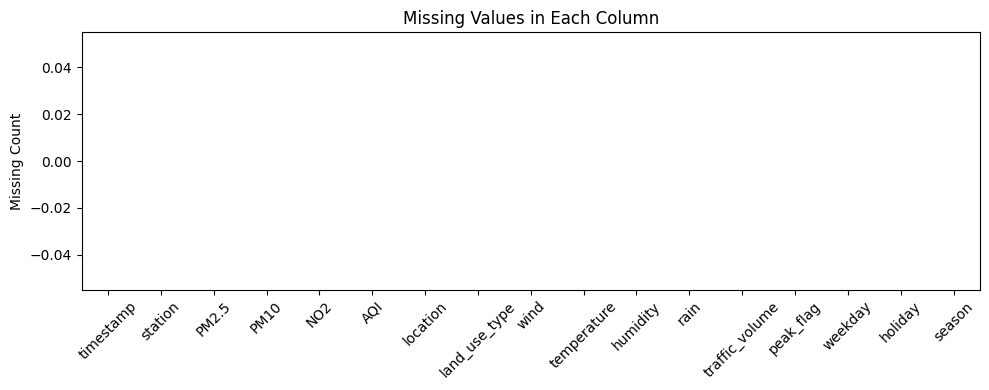

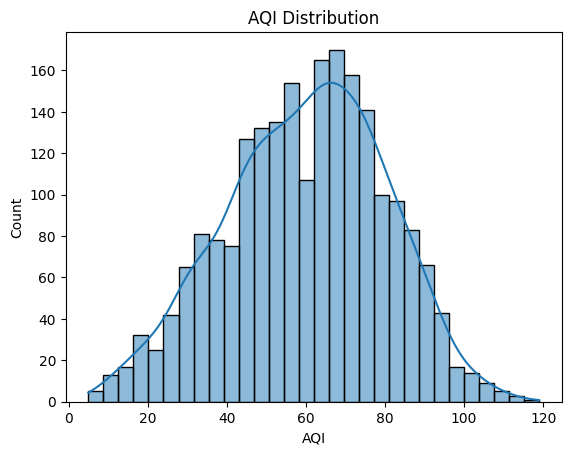

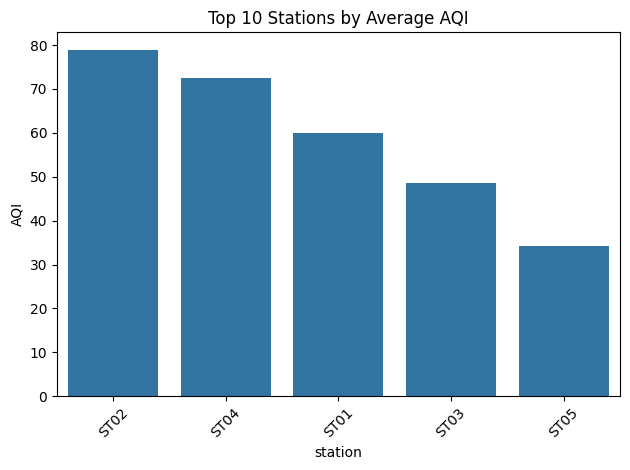

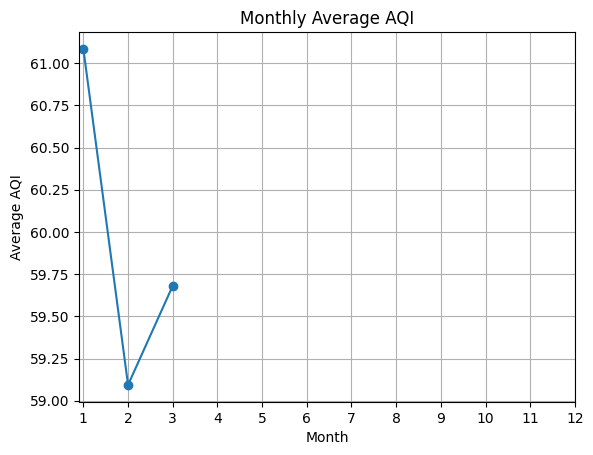

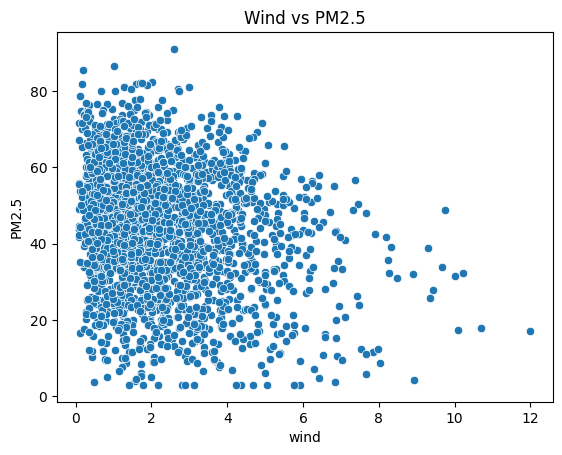

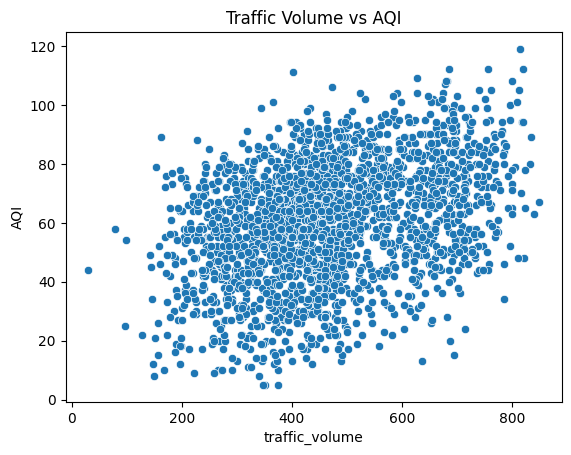

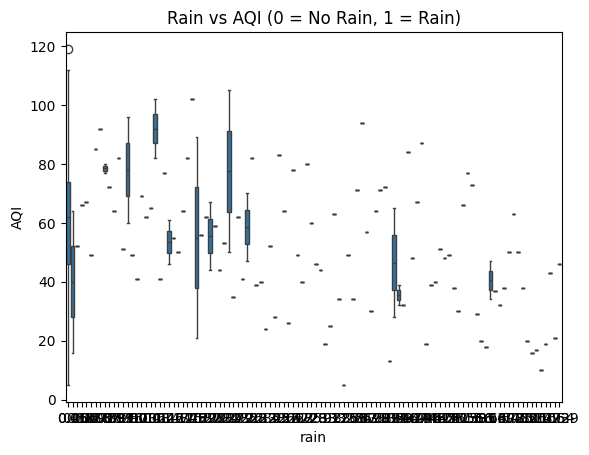

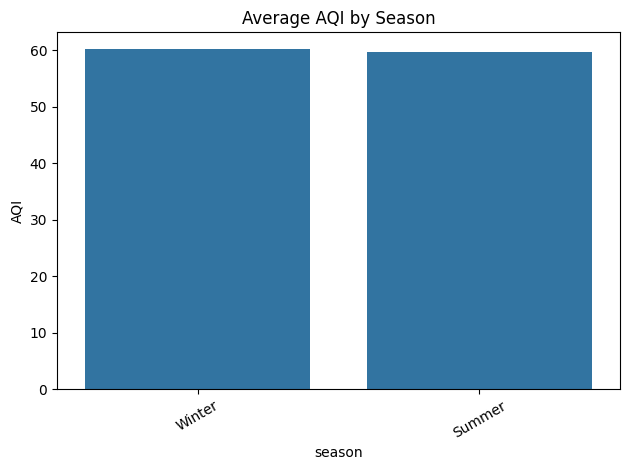

In [18]:
# 1. Descriptive Statistics
display(df.describe().round(2))

# 2. Missing Values Visualization
df.isnull().sum().plot(kind="bar", figsize=(10, 4))
plt.title("Missing Values in Each Column")
plt.ylabel("Missing Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. AQI Distribution
sns.histplot(df["AQI"].dropna(), bins=30, kde=True)
plt.title("AQI Distribution")
plt.xlabel("AQI")
plt.show()

# 4. Top 10 Stations by Average AQI
top10 = (df.groupby("station")["AQI"].mean()
         .dropna().nlargest(10).reset_index())

sns.barplot(data=top10, x="station", y="AQI")
plt.title("Top 10 Stations by Average AQI")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 5. Average AQI by Month
df["Month"] = df["timestamp"].dt.month
monthly_aqi = df.groupby("Month")["AQI"].mean()

monthly_aqi.plot(kind="line", marker="o")
plt.title("Monthly Average AQI")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

# 6. Average AQI by Weather and Traffic
sns.scatterplot(data=df, x="wind", y="PM2.5")
plt.title("Wind vs PM2.5")
plt.show()

sns.scatterplot(data=df, x="traffic_volume", y="AQI")
plt.title("Traffic Volume vs AQI")
plt.show()

# 7. Rain Effect on AQI
sns.boxplot(data=df, x="rain", y="AQI")
plt.title("Rain vs AQI (0 = No Rain, 1 = Rain)")
plt.show()

# 8. Average AQI by Season
sns.barplot(data=df, x="season", y="AQI",
            estimator="mean", errorbar=None)
plt.title("Average AQI by Season")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**5. Study important relationships, patterns, and trends**

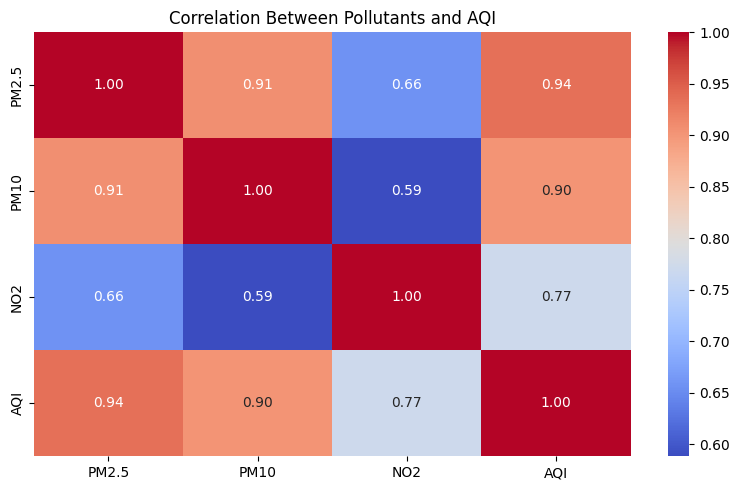

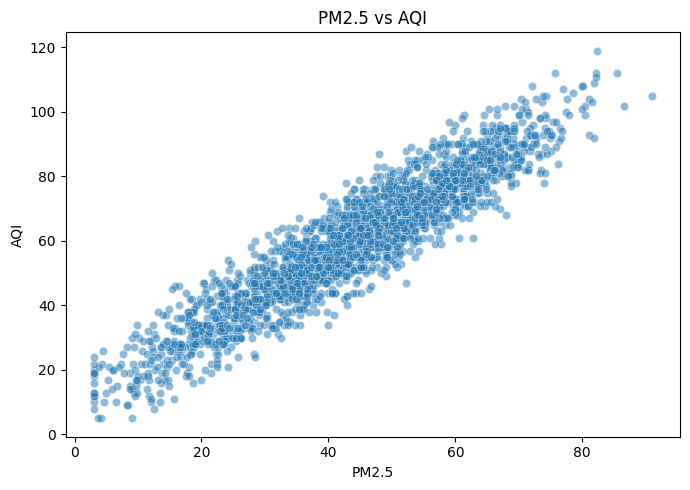

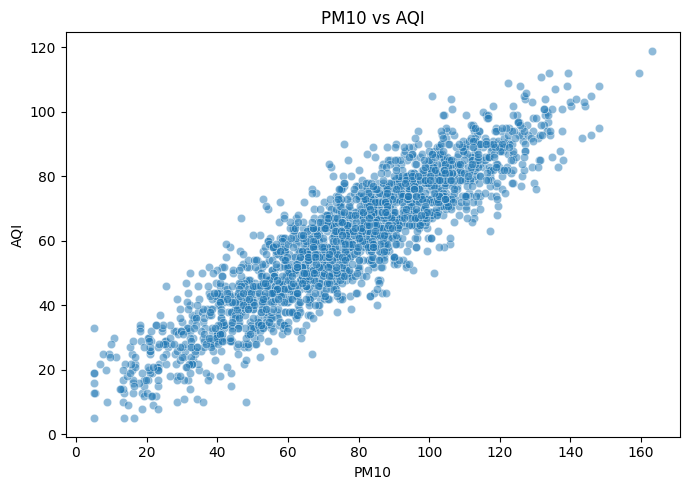

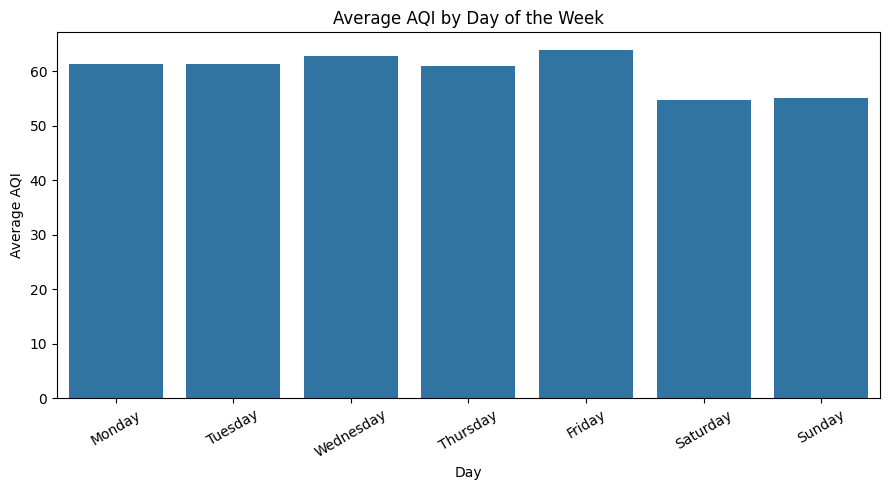

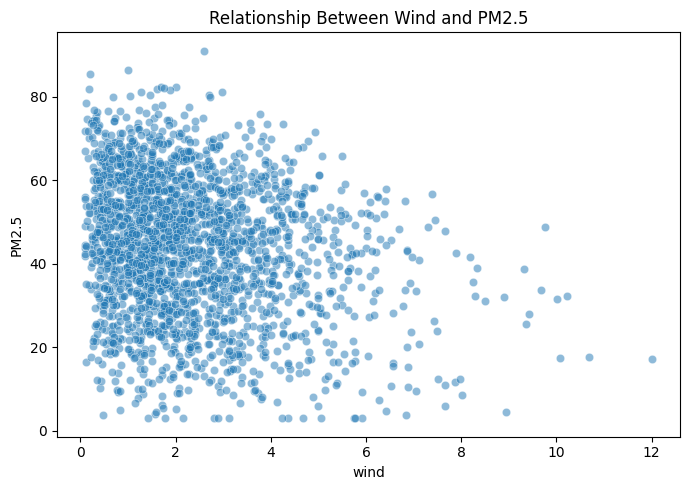

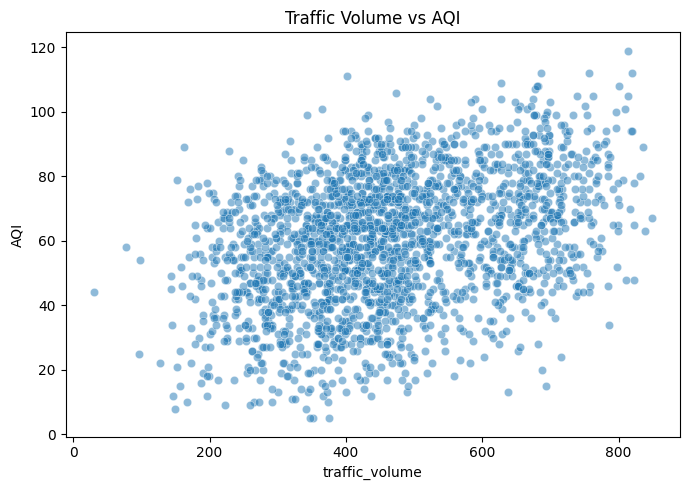

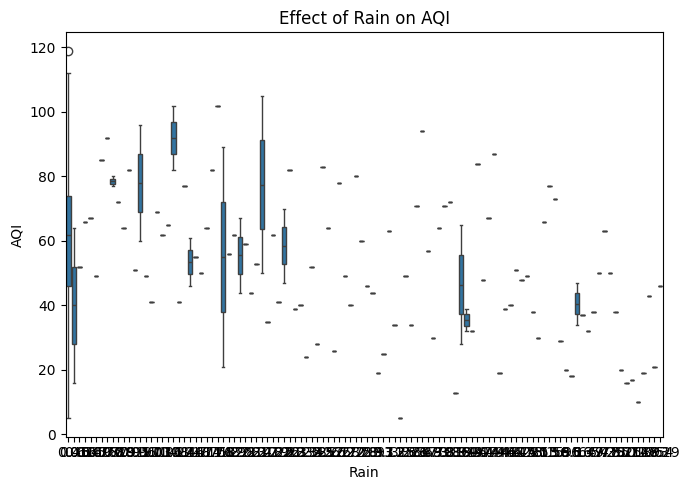

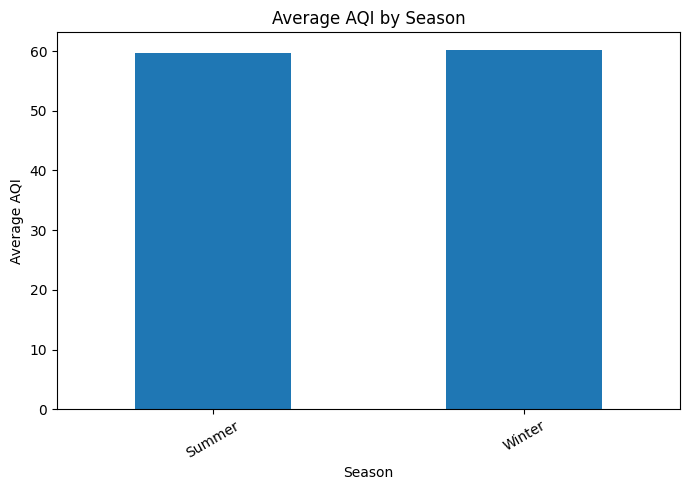

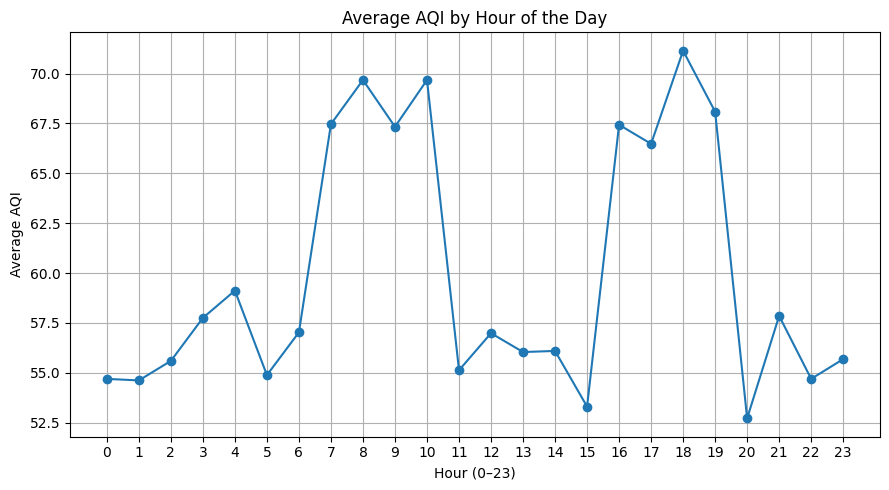

In [19]:

# 1. Correlation between pollutants
pollutants = ["PM2.5", "PM10", "NO2", "AQI"]
pollutants = [col for col in pollutants if col in df.columns]

plt.figure(figsize=(8, 5))
sns.heatmap(df[pollutants].corr(), annot=True,
            cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Pollutants and AQI")
plt.tight_layout()
plt.show()


# 2. PM2.5 vs AQI
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="PM2.5", y="AQI", alpha=0.5)
plt.title("PM2.5 vs AQI")
plt.tight_layout()
plt.show()


# 3. PM10 vs AQI
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="PM10", y="AQI", alpha=0.5)
plt.title("PM10 vs AQI")
plt.tight_layout()
plt.show()


# 4. Average AQI by Day of the Week
df["Day"] = df["timestamp"].dt.day_name()

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday",
             "Friday", "Saturday", "Sunday"]

day_aqi = df.groupby("Day")["AQI"].mean().reindex(day_order)

plt.figure(figsize=(9, 5))
sns.barplot(x=day_aqi.index, y=day_aqi.values)
plt.title("Average AQI by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Average AQI")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# 5. Wind vs PM2.5
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="wind", y="PM2.5", alpha=0.5)
plt.title("Relationship Between Wind and PM2.5")
plt.tight_layout()
plt.show()


# 6. Traffic Volume vs AQI
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="traffic_volume", y="AQI", alpha=0.5)
plt.title("Traffic Volume vs AQI")
plt.tight_layout()
plt.show()


# 7. Rain Effect on AQI
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="rain", y="AQI")
plt.title("Effect of Rain on AQI")
plt.xlabel("Rain")
plt.ylabel("AQI")
plt.tight_layout()
plt.show()


# 8. Average AQI by Season
season_aqi = df.groupby("season", observed=True)["AQI"].mean().dropna()

plt.figure(figsize=(7, 5))
season_aqi.plot(kind="bar")
plt.title("Average AQI by Season")
plt.xlabel("Season")
plt.ylabel("Average AQI")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# 9. Average AQI by Hour
df["Hour"] = df["timestamp"].dt.hour
hour_aqi = df.groupby("Hour")["AQI"].mean()

plt.figure(figsize=(9, 5))
hour_aqi.plot(kind="line", marker="o")
plt.title("Average AQI by Hour of the Day")
plt.xlabel("Hour (0–23)")
plt.ylabel("Average AQI")
plt.xticks(range(0, 24))
plt.grid(True)
plt.tight_layout()
plt.show()


**6. Encode categorical variables where required**

In [20]:

# Select categorical columns
cat_cols = df.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

print("Categorical Columns:", cat_cols)

# Convert categorical columns into numerical columns
encoded_data = pd.get_dummies(
    df,
    columns=cat_cols,
    drop_first=True,
    dtype=int
)

print("Shape Before Encoding:", df.shape)
print("Shape After Encoding:", encoded_data.shape)

display(encoded_data.head())


Categorical Columns: ['station', 'location', 'land_use_type', 'weekday', 'season', 'Day']
Shape Before Encoding: (2160, 20)
Shape After Encoding: (2160, 39)


,timestamp,PM2.5,PM10,NO2,AQI,wind,temperature,humidity,rain,traffic_volume,...,weekday_Thursday,weekday_Tuesday,weekday_Wednesday,season_Winter,Day_Monday,Day_Saturday,Day_Sunday,Day_Thursday,Day_Tuesday,Day_Wednesday
0,2026-01-01 00:00:00,51.2,101.4,40.3,69,1.70,23.6,73.5,0.0,408,...,1,0,0,1,0,0,0,1,0,0
1,2026-01-01 01:00:00,74.9,130.8,44.0,92,2.58,22.5,85.9,0.0,498,...,1,0,0,1,0,0,0,1,0,0
2,2026-01-01 02:00:00,9.1,5.0,11.8,5,3.74,23.6,73.6,0.0,352,...,1,0,0,1,0,0,0,1,0,0
3,2026-01-01 03:00:00,53.2,99.5,43.6,68,3.48,23.0,67.7,0.0,580,...,1,0,0,1,0,0,0,1,0,0
4,2026-01-01 04:00:00,34.9,77.7,27.6,50,3.10,24.6,75.8,0.0,353,...,1,0,0,1,0,0,0,1,0,0


**7. Feature Engineering**

In [21]:

# Convert timestamp to datetime format
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

# Create new features
df["Hour"] = df["timestamp"].dt.hour
df["Month"] = df["timestamp"].dt.month
df["DayOfWeek"] = df["timestamp"].dt.day_name()
df["IsWeekend"] = (df["timestamp"].dt.dayofweek >= 5).astype(int)

# Create seasonal feature if not already present
if "season" not in df.columns:
    df["Season"] = df["Month"].map({
        12: "Winter", 1: "Winter", 2: "Winter",
        3: "Summer", 4: "Summer", 5: "Summer",
        6: "Monsoon", 7: "Monsoon",
        8: "Monsoon", 9: "Monsoon",
        10: "Post-Monsoon", 11: "Post-Monsoon"
    })
else:
    df["Season"] = df["season"]

# Display the new features
display(df[["timestamp", "Hour", "Month",
            "DayOfWeek", "IsWeekend", "Season"]].head())

print("New Dataset Shape:", df.shape)


,timestamp,Hour,Month,DayOfWeek,IsWeekend,Season
0,2026-01-01 00:00:00,0,1,Thursday,0,Winter
1,2026-01-01 01:00:00,1,1,Thursday,0,Winter
2,2026-01-01 02:00:00,2,1,Thursday,0,Winter
3,2026-01-01 03:00:00,3,1,Thursday,0,Winter
4,2026-01-01 04:00:00,4,1,Thursday,0,Winter


New Dataset Shape: (2160, 23)


**8. Feature Selection or Dimensionality Reduction**

In [22]:

from sklearn.feature_selection import SelectKBest, f_regression

# Select numerical features, excluding AQI
features = df.select_dtypes(include=np.number).drop(
    columns=["AQI"], errors="ignore"
)

# Keep rows where AQI is available
data_clean = df.dropna(subset=["AQI"]).copy()

X = features.loc[data_clean.index].copy()
y = data_clean["AQI"]

# Fill missing feature values with their median
X = X.fillna(X.median())

# Remove columns that contain only missing values or have no variation
X = X.dropna(axis=1, how="all")
X = X.loc[:, X.nunique() > 1]

# Select the top 5 features
if X.shape[1] > 0:
    k = min(5, X.shape[1])

    selector = SelectKBest(score_func=f_regression, k=k)
    selector.fit(X, y)

    # Display feature scores
    selected = pd.DataFrame({
        "Feature": X.columns,
        "Score": selector.scores_
    }).sort_values("Score", ascending=False)

    print("Top Features for Predicting AQI:")
    display(selected.head(k).round(2))

    # Store selected feature names
    selected_features = selected.head(k)["Feature"].tolist()
    print("Selected Features:", selected_features)

else:
    print("No suitable numerical features available.")


Top Features for Predicting AQI:


,Feature,Score
0,PM2.5,15090.55
1,PM10,9544.40
2,NO2,3167.39
7,traffic_volume,337.25
8,peak_flag,207.23


Selected Features: ['PM2.5', 'PM10', 'NO2', 'traffic_volume', 'peak_flag']


In [24]:

# Save the cleaned dataset
df.to_csv("cleaned_air_quality.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Final Dataset Shape:", df.shape)

display(df.head())


Cleaned dataset saved successfully!
Final Dataset Shape: (2160, 23)


,timestamp,station,PM2.5,PM10,NO2,AQI,location,land_use_type,wind,temperature,...,peak_flag,weekday,holiday,season,Month,Day,Hour,DayOfWeek,IsWeekend,Season
0,2026-01-01 00:00:00,ST04,51.2,101.4,40.3,69,Highway Junction,transport,1.70,23.6,...,0,Thursday,1,Winter,1,Thursday,0,Thursday,0,Winter
1,2026-01-01 01:00:00,ST02,74.9,130.8,44.0,92,Industrial Area,industrial,2.58,22.5,...,0,Thursday,1,Winter,1,Thursday,1,Thursday,0,Winter
2,2026-01-01 02:00:00,ST05,9.1,5.0,11.8,5,Urban Park,green_space,3.74,23.6,...,0,Thursday,1,Winter,1,Thursday,2,Thursday,0,Winter
3,2026-01-01 03:00:00,ST04,53.2,99.5,43.6,68,Highway Junction,transport,3.48,23.0,...,0,Thursday,1,Winter,1,Thursday,3,Thursday,0,Winter
4,2026-01-01 04:00:00,ST01,34.9,77.7,27.6,50,City Center,commercial,3.10,24.6,...,0,Thursday,1,Winter,1,Thursday,4,Thursday,0,Winter



1. Top 10 Stations with Highest Average AQI:


,AQI
station,
ST02,78.96
ST04,72.59
ST01,60.06
ST03,48.67
ST05,34.28



2. Hour with Highest Average AQI: 18


,AQI
Hour,
0,54.70
1,54.62
2,55.60
3,57.76
4,59.12
5,54.89
6,57.03
7,67.47
8,69.68



3. Correlation between Wind and PM2.5: -0.22

4. Correlation between Traffic Volume and AQI: 0.368

5. Pollution by Rain Status:


,Average_AQI,Average_PM25
Rain_Status,,
No Rain,60.43,44.36
Rain,52.29,35.39



6. Average AQI by Season:


,AQI
Season,
Winter,60.14
Summer,59.68


Season with Highest Average AQI: Winter


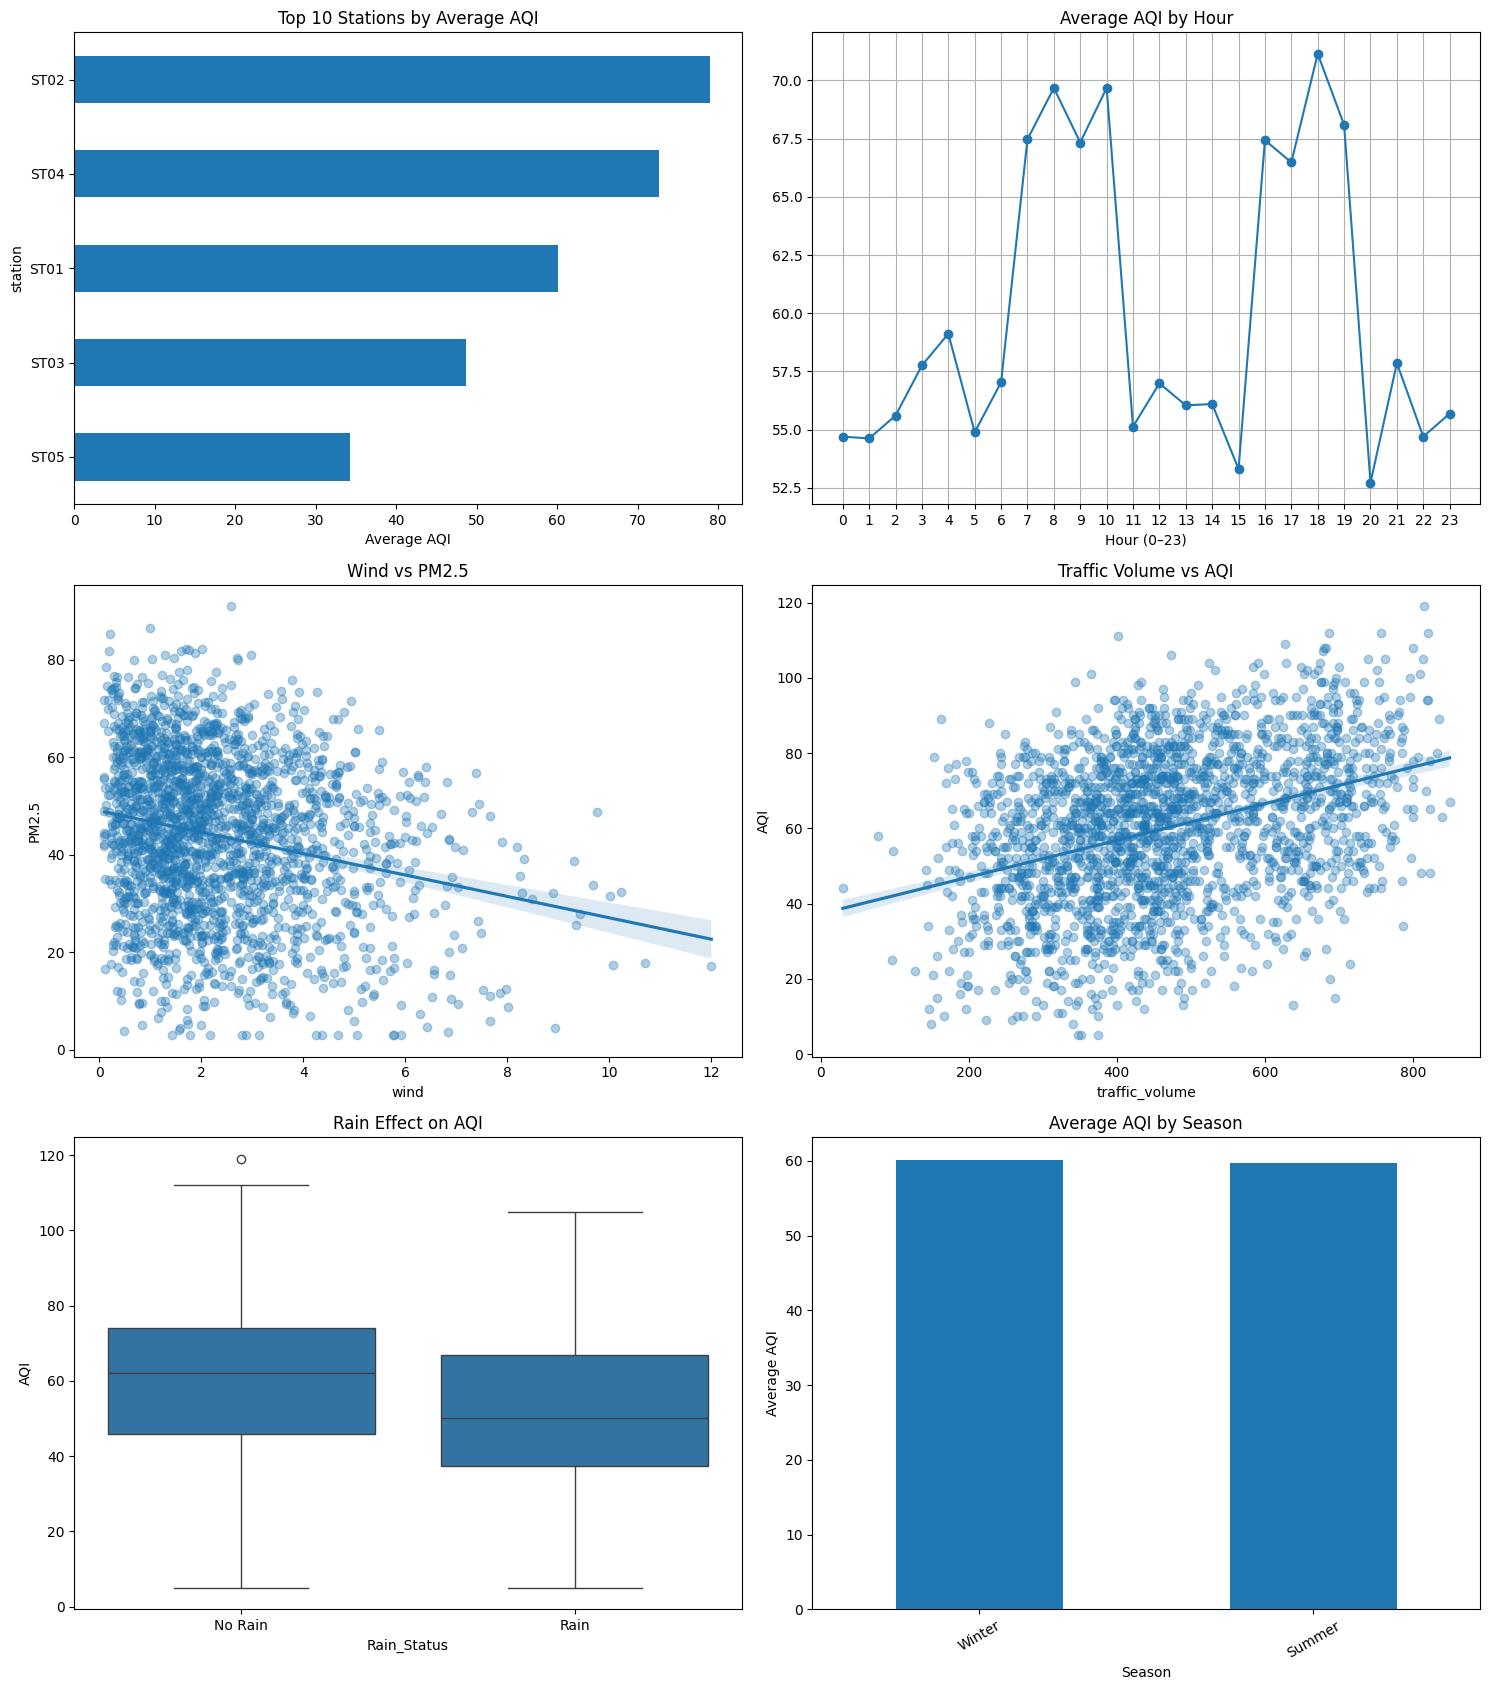

In [25]:
# 1. Stations with poorer air quality
station_aqi = df.groupby("station")["AQI"].mean().dropna().sort_values(ascending=False)
print("\n1. Top 10 Stations with Highest Average AQI:")
display(station_aqi.head(10).round(2))

# 2. Times with higher pollution
hourly_aqi = df.groupby("Hour")["AQI"].mean().dropna()
print("\n2. Hour with Highest Average AQI:", hourly_aqi.idxmax())
display(hourly_aqi.round(2))

# 3. Wind vs PM2.5
wind_data = df[["wind", "PM2.5"]].dropna()
wind_corr = wind_data["wind"].corr(wind_data["PM2.5"])
print("\n3. Correlation between Wind and PM2.5:", round(wind_corr, 3))

# 4. Traffic volume vs AQI
traffic_data = df[["traffic_volume", "AQI"]].dropna()
traffic_corr = traffic_data["traffic_volume"].corr(traffic_data["AQI"])
print("\n4. Correlation between Traffic Volume and AQI:", round(traffic_corr, 3))

# 5. Rain effect on pollution
rain_data = df[["rain", "AQI", "PM2.5"]].dropna().copy()

if set(rain_data["rain"].unique()).issubset({0, 1}):
    rain_data["Rain_Status"] = rain_data["rain"].map({0: "No Rain", 1: "Rain"})
else:
    rain_data["Rain_Status"] = np.where(
        rain_data["rain"] > 0, "Rain", "No Rain"
    )

rain_summary = rain_data.groupby("Rain_Status").agg(
    Average_AQI=("AQI", "mean"),
    Average_PM25=("PM2.5", "mean")
)
print("\n5. Pollution by Rain Status:")
display(rain_summary.round(2))

# 6. Seasonal pollution peaks
season_aqi = df.groupby("Season")["AQI"].mean().dropna().sort_values(ascending=False)
print("\n6. Average AQI by Season:")
display(season_aqi.round(2))
if not season_aqi.empty:
    print("Season with Highest Average AQI:", season_aqi.idxmax())

# Visualizations
fig, axes = plt.subplots(3, 2, figsize=(15, 17))

# Station AQI
station_aqi.head(10).sort_values().plot(kind="barh", ax=axes[0, 0])
axes[0, 0].set_title("Top 10 Stations by Average AQI")
axes[0, 0].set_xlabel("Average AQI")

# Hourly AQI
hourly_aqi.plot(kind="line", marker="o", ax=axes[0, 1])
axes[0, 1].set_title("Average AQI by Hour")
axes[0, 1].set_xlabel("Hour (0–23)")
axes[0, 1].set_xticks(range(0, 24))
axes[0, 1].grid(True)

# Wind vs PM2.5
sns.regplot(data=wind_data, x="wind", y="PM2.5",
            scatter_kws={"alpha": 0.35}, ax=axes[1, 0])
axes[1, 0].set_title("Wind vs PM2.5")

# Traffic vs AQI
sns.regplot(data=traffic_data, x="traffic_volume", y="AQI",
            scatter_kws={"alpha": 0.35}, ax=axes[1, 1])
axes[1, 1].set_title("Traffic Volume vs AQI")

# Rain vs AQI
sns.boxplot(data=rain_data, x="Rain_Status", y="AQI", ax=axes[2, 0])
axes[2, 0].set_title("Rain Effect on AQI")

# Seasonal AQI
season_aqi.plot(kind="bar", ax=axes[2, 1])
axes[2, 1].set_title("Average AQI by Season")
axes[2, 1].set_ylabel("Average AQI")
axes[2, 1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()
